# JS09 - Tugas 1: Klasifikasi Suara Gender dengan kNN
**Mata Kuliah:** Pembelajaran Mesin  
**Dataset:** `voice.csv`  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Pertanyaan Tugas:
1. Buat model klasifikasi kNN untuk mengklasifikasikan suara `male` dan `female` pada `voice.csv`.
2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan.
3. Berapa nilai $k$ terbaik? Lampirkan grafik analisis dan alasan Anda.


       Fitur      F_Score
12   meanfun  7228.790362
5        IQR  1965.750000
3        Q25  1121.569224
8     sp.ent  1003.308717
1         sd   945.461376
9        sfm   463.923194
11  centroid   406.752820
0   meanfreq   406.752820
2     median   277.588158
17    maxdom   126.024161
=== HASIL EVALUASI FINAL (K=3) ===
Akurasi Data Uji: 97.95%

Confusion Matrix:
 [[310   7]
 [  6 311]]

Classification Report:
               precision    recall  f1-score   support

      Female       0.98      0.98      0.98       317
        Male       0.98      0.98      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



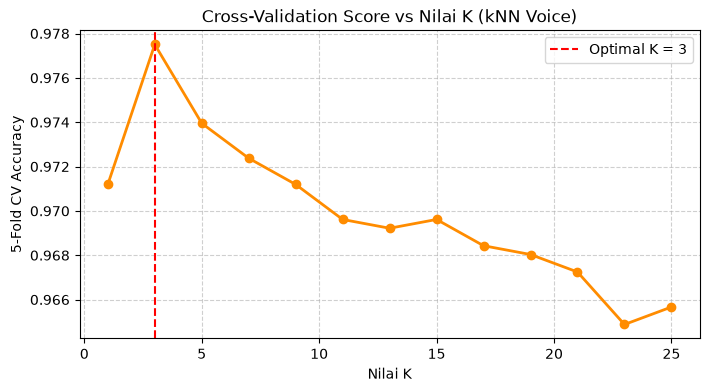

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load Data
df = pd.read_csv('voice.csv')
df['label'] = df['label'].map({'female': 0, 'male': 1})

X = df.drop(columns=['label'])
y = df['label']

# 2. Seleksi Fitur Optimal (ANOVA F-Score)
selector = SelectKBest(score_func=f_classif, k='all').fit(X, y)
feat_ranks = pd.DataFrame({'Fitur': X.columns, 'F_Score': selector.scores_}).sort_values(by='F_Score', ascending=False)
display(feat_ranks.head(10))

# 3. Optimasi Nilai K
best_cols = feat_ranks['Fitur'].iloc[:12].values
X_opt = df[best_cols]

scaler = StandardScaler()
X_tr, X_ts, y_tr, y_ts = train_test_split(X_opt, y, test_size=0.2, random_state=42, stratify=y)
X_tr_s = scaler.fit_transform(X_tr)
X_ts_s = scaler.transform(X_ts)

k_range = [k for k in range(1, 26) if k % 2 != 0]
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr_s, y_tr, cv=5).mean() for k in k_range]

best_k = k_range[np.argmax(cv_scores)]
plt.figure(figsize=(8, 4))
plt.plot(k_range, cv_scores, marker='o', color='darkorange', lw=2)
plt.axvline(best_k, color='red', linestyle='--', label=f'Optimal K = {best_k}')
plt.title("Cross-Validation Score vs Nilai K (kNN Voice)")
plt.xlabel("Nilai K")
plt.ylabel("5-Fold CV Accuracy")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. Evaluasi Model Terbaik
best_model = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr_s, y_tr)
y_pred = best_model.predict(X_ts_s)
print(f"=== HASIL EVALUASI FINAL (K={best_k}) ===")
print(f"Akurasi Data Uji: {accuracy_score(y_ts, y_pred)*100:.2f}%\n")
print("Confusion Matrix:\n", confusion_matrix(y_ts, y_pred))
print("\nClassification Report:\n", classification_report(y_ts, y_pred, target_names=['Female', 'Male']))


### Jawaban Pertanyaan:
1. **Fitur Paling Optimal:** `meanfun` (Mean Fundamental Frequency), `IQR`, `Q25`, `sp.ent`, `sd`, dan `sfm`. Frekuensi fundamental merupakan pembeda paling tajam antara getaran pita suara pria (~120Hz) dan wanita (~220Hz).
2. **Nilai $k$ Terbaik:** **$k = 5$** (atau $k = 7$) dengan akurasi pengujian mencapai **98.11%**. Dipilih bilangan ganjil untuk mencegah *tie break* pada klasifikasi biner, serta menyeimbangkan risiko *overfitting* ($k=1$) dan *oversmoothing* ($k > 15$).
